# Exploring OpenFEMA Data for TMPI Use

This notebook pulls and explores data from the OpenFEMA API using Pandas, emulates some data cleaning and methods from the Urban Institute's [Disaster Data Tribes repository](https://github.com/UrbanInstitute/disaster-data-tribes) (translating from R to Python), including visualizations of Hazard Mitigation Assistance (HMA) grant distribution.

### Imports

In [108]:
from datetime import date
from pathlib import Path
import config
import requests
import janitor
import pandas as pd
import numpy as np

## Obtaining Data

The code cell below is a reusable function to download data from OpenFEMA API responses. It saves the dataset as a dated Parquet file, allowing it to avoid re-downloading the dataset if a snapshot at the current date already exists.

In [109]:
def get_openfema_snapshot(box_dir=config.OPENFEMA_DIR, api_filter=None, overwrite=False):
    box_dir.mkdir(parents=True, exist_ok=True)
    
    snapshot_date = date.today().strftime("%Y_%m_%d")
    out_path = box_dir / f"HmaSubapplications_{snapshot_date}.parquet"

    if out_path.exists() and not overwrite:
        print(f"Using existing snapshot: {out_path.name}")
        return pd.read_parquet(out_path)
    
    url = "https://www.fema.gov/api/open/v2/HmaSubapplications"
    
    records = []
    skip = 0
    top = 10000

    while True:
        params = {"$top": top,"$skip": skip, "$orderby": "id"}
        if api_filter:
            params["$filter"] = api_filter

        response = requests.get(url, params=params, timeout=60)

        if response.status_code != 200:
            print(f"Failed to fetch data at skip = {skip}: {response.status_code}")
            return None

        batch = response.json().get("HmaSubapplications",[])
        if not batch:
            break

        records.extend(batch)
        print(f"Fetched {len(records):,} records so far...")

        if len(batch) < top:
            break

        skip += top

    declarations = pd.DataFrame(records).clean_names(case_type="snake")
    declarations.to_parquet(out_path, index=False)
    print(f"Saved {len(declarations):,} records to {out_path.name}")
    return declarations

In [110]:
hma = get_openfema_snapshot()

Using existing snapshot: HmaSubapplications_2026_11_24.parquet


In [111]:
hma.info()

<class 'pandas.DataFrame'>
RangeIndex: 63647 entries, 0 to 63646
Data columns (total 89 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   subapplication_identifier               63647 non-null  str    
 1   program                                 63647 non-null  str    
 2   fiscal_year                             63647 non-null  int64  
 3   region                                  63647 non-null  int64  
 4   applicant_uei                           13450 non-null  str    
 5   applicant_name                          63647 non-null  str    
 6   subapplicant_uei                        6927 non-null   str    
 7   subapplicant_name                       63647 non-null  str    
 8   subapplicant_city                       19250 non-null  str    
 9   subapplicant_state                      63638 non-null  str    
 10  subapplicant_state_abbreviation         54983 non-null  str    
 11  

In [112]:
hma.describe(include='all')

,subapplication_identifier,program,fiscal_year,region,applicant_uei,applicant_name,subapplicant_uei,subapplicant_name,subapplicant_city,subapplicant_state,...,benefit_cost_ratio,bca_total_benefits,bca_total_costs,disaster_number,selection_status,selection_funding_category,selection_program_activity,selection_federal_share_amount,selection_fund_code,id
count,63647,63647,63647.000000,63647.000000,13450,63647,6927,63647,19250,63638,...,3.775500e+04,5.230600e+04,5.081100e+04,43277,4944,4740,2646,2.673000e+03,2668,63647
unique,63647,11,NaN,NaN,269,744,2974,20534,5085,58,...,NaN,NaN,NaN,2088,4,16,7,NaN,5,63647
top,DR-1437-0029-R,Hazard Mitigation Grant Program,NaN,NaN,N6KVCUU7LC61,Statewide,N6KVCUU7LC61,Statewide,Miami,Florida,...,NaN,NaN,NaN,1971,Identified for Further Review,National Competition,Mitigation Project,NaN,6M,00007fee-ef94-4273-9477-70e7e8638944
freq,1,42176,NaN,NaN,793,35492,102,2989,163,6367,...,NaN,NaN,NaN,734,2668,1302,1485,NaN,1048,1
mean,NaN,NaN,2011.790752,5.219838,NaN,NaN,NaN,NaN,NaN,NaN,...,1.848700e+02,3.824888e+07,2.388572e+06,NaN,NaN,NaN,NaN,2.465572e+06,NaN,NaN
std,NaN,NaN,9.535924,2.454040,NaN,NaN,NaN,NaN,NaN,NaN,...,1.888750e+04,3.078593e+09,1.954716e+07,NaN,NaN,NaN,NaN,7.391469e+06,NaN,NaN
min,NaN,NaN,1989.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,0.000000e+00,-8.000000e+01,0.000000e+00,NaN,NaN,NaN,NaN,1.125000e+03,NaN,NaN
25%,NaN,NaN,2005.000000,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,1.080000e+00,0.000000e+00,0.000000e+00,NaN,NaN,NaN,NaN,7.500000e+04,NaN,NaN
50%,NaN,NaN,2013.000000,5.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,1.600000e+00,3.009340e+05,1.734670e+05,NaN,NaN,NaN,NaN,2.280000e+05,NaN,NaN
75%,NaN,NaN,2020.000000,7.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,3.300000e+00,2.345222e+06,1.011694e+06,NaN,NaN,NaN,NaN,9.000000e+05,NaN,NaN


In [113]:
required_columns = [
    "date_submitted_to_fema",
    "selection_federal_share_amount",
    "program",
    "primary_activity",
    "selection_status",
    "subapplicant_type",
    "subapplicant_state_abbreviation",
    "benefiting_counties"]

column_check = pd.DataFrame({
    "column": required_columns,
    "exists": [col in hma.columns for col in required_columns]
})

display(column_check)

,column,exists
0,date_submitted_to_fema,True
1,selection_federal_share_amount,True
2,program,True
3,primary_activity,True
4,selection_status,True
5,subapplicant_type,True
6,subapplicant_state_abbreviation,True
7,benefiting_counties,True


In [114]:
hma[
    [
        "date_submitted_to_fema",
        "selection_federal_share_amount",
        "program",
        "primary_activity",
        "selection_status",
    ]
].head(10)

,date_submitted_to_fema,selection_federal_share_amount,program,primary_activity,selection_status
0,2003-03-21T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Utility and infrastructure protection,NaN
1,2003-05-23T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Saferoom/shelter,NaN
2,2025-05-23T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Acquisition,NaN
3,2010-11-16T00:00:00.000Z,NaN,Pre-Disaster Mitigation,Stabilization and restoration,NaN
4,2013-06-26T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Acquisition,NaN
5,2024-09-30T00:00:00.000Z,NaN,Hazard Mitigation Grant Program Post Fire,Wildfire management,NaN
6,2024-02-21T00:00:00.000Z,NaN,Building Resilient Infrastructure and Communities,"Develop or conduct engineering, environmental,...",Did Not Meet HMA Requirements
7,2022-09-08T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Plan update,NaN
8,2023-01-27T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Flood control,NaN
9,2024-04-15T00:00:00.000Z,NaN,Hazard Mitigation Grant Program,Generator,NaN


In [115]:
hma["program"].value_counts(dropna=False)

program
Hazard Mitigation Grant Program                                       42176
Pre-Disaster Mitigation                                                7922
Flood Mitigation Assistance                                            5980
Building Resilient Infrastructure and Communities                      4871
Hazard Mitigation Grant Program Post Fire                               989
Legislative Pre-Disaster Mitigation                                     414
Flood Mitigation Assistance Swift Current                               407
Pre-Disaster Mitigation Congressionally Directed Spending               319
Severe Repetitive Loss                                                  306
Repetitive Flood Claims                                                 151
Fire Management Assistance Grant - Hazard Mitigation Grant Program      112
Name: count, dtype: int64

_**Note:** the Urban Institute's figure 7 on BRIC funding excludes Flood Mitigation Assistance, Repetitive Flood Claims, and Severe Repetitive Loss, as these awards to indigenous communities are negligible. I am not excluding them._

In [116]:
hma["selection_status"].value_counts(dropna=False)

selection_status
NaN                              58703
Identified for Further Review     2668
Not Selected                      1301
Did Not Meet HMA Requirements      967
Withdrawn                            8
Name: count, dtype: int64

## Cleaning

The code below largely follows the same cleaning steps/assumptings as the Urban Institute's R code from their repository.
1. Extract the year from `date_submitted_to_fema`
1. Keep years 2000 - 2026
1. Exclude records with selection statuses:
   - `Did Not Meet HMA Requirements`
   - `Not Selected`
   - `Withdrawn`
   - Missing status
1. Use `selection_federal_share_amount` as the funding amount
1. Use `primary_activity` as the project type

In [ ]:
hma_clean = hma.copy()

hma_clean["date_submitted_to_fema"] = pd.to_datetime(
    hma_clean["date_submitted_to_fema"], errors="coerce"
)

hma_clean["year"] = hma_clean["date_submitted_to_fema"].dt.year

hma_clean["amount"] = pd.to_numeric(
    hma_clean["selection_federal_share_amount"], errors="coerce"
)
hma_clean = hma_clean[hma_clean["year"].between(2000,2026)].copy()

awarded_statuses = {
    "Approved",
    "Awarded",
    "Closed",
    "Closeout Initiated",
    "Obligated",
    "Subaward Accepted",
}

is_awarded = hma_clean["status"].isin(awarded_statuses) | (
    hma_clean["selection_status"].eq("Identified for Further Review")
    & ~hma_clean["status"].isin(["Not Selected", "Ineligible", "Withdrawn", "Void"])
)
hma_clean = hma_clean[is_awarded].copy()

sel_amt = pd.to_numeric(hma_clean["selection_federal_share_amount"], errors="coerce")
ob_amt = pd.to_numeric(hma_clean["total_obligated_amount"], errors="coerce")
fed_amt = pd.to_numeric(hma_clean["federal_share_amount"], errors="coerce")

hma_clean["amount"] = sel_amt.combine_first(ob_amt).combine_first(fed_amt)

# standardizing program names for consistency with UI's visualization
hma_clean["program"] = hma_clean["program"].str.replace(r".*Building.*", "BRIC", case=False, regex=True)
hma_clean["program"] = hma_clean["program"].str.replace(r".*Hazard Mitigation Grant Program.*", "HMGP", case=False, regex=True)
hma_clean["program"] = hma_clean["program"].str.replace(r".*Pre-Disaster.*", "PDM", case=False, regex=True)
hma_clean["program"] = hma_clean["program"].str.replace(r".*Legislative Pre-Disaster Mitigation.*", "LPDM", case=False, regex=True)
hma_clean["program"] = hma_clean["program"].str.replace(r".*Flood Mitigation Assistance.*|Severe Repetitive Loss|Repetitive Flood Claims", "FMA", case=False, regex=True)

print(f"Original records: {len(hma):,}")
print(f"Records after cleaning: {len(hma_clean):,}")

Original records: 63,647
Records after cleaning: 42,283


## Describing & Summarizing Needed Columns

In [118]:
figure_summary = pd.DataFrame({
    "Variable": [
        "Year",
        "Funding amount",
        "Program type",
        "Project type",
    ],
    "Source column": [
        "date_submitted_to_fema",
        "selection_federal_share_amount",
        "program",
        "primary_activity",
    ],
    "Meaning": [
        "Year submitted to FEMA",
        "Selected federal share in dollars",
        "HMA grant program",
        "Primary mitigation activity",
    ],
    "Missing values": [
        hma_clean["year"].isna().sum(),
        hma_clean["amount"].isna().sum(),
        hma_clean["program"].isna().sum(),
        hma_clean["primary_activity"].isna().sum(),
    ],
})

display(figure_summary)

,Variable,Source column,Meaning,Missing values
0,Year,date_submitted_to_fema,Year submitted to FEMA,0
1,Funding amount,selection_federal_share_amount,Selected federal share in dollars,78
2,Program type,program,HMA grant program,0
3,Project type,primary_activity,Primary mitigation activity,13


In [119]:
program_summary = (
    hma_clean
    .groupby("program")
    .agg(
        records=("amount", "size"),
        total_funding=("amount", "sum"),
        average_funding=("amount", "mean"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .sort_values("total_funding", ascending=False)
)

display(program_summary)
display(hma_clean["program"].value_counts())

,records,total_funding,average_funding,first_year,last_year
program,,,,,
HMGP,31860,2.143446e+10,6.742304e+05,2000.0,2026.0
BRIC,1870,4.546410e+09,2.431235e+06,2020.0,2024.0
FMA,3300,3.492262e+09,1.058261e+06,2000.0,2025.0
PDM,5253,2.056763e+09,3.922126e+05,2001.0,2026.0


program
HMGP    31860
PDM      5253
FMA      3300
BRIC     1870
Name: count, dtype: int64

## Aggregating & Visualizing

As I noted above, I will not be excluding FMA or its predecessors.

In [120]:
figure_7_data = (
    hma_clean
    .dropna(subset=["year", "program"])
    .groupby(["year", "program"], as_index=False)
    .agg(
        federal_share_amount=("amount", "sum"),
        n_awards=("amount", "size")
    )
)

figure_7_data["program"].value_counts()

program
HMGP    27
FMA     25
PDM     24
BRIC     5
Name: count, dtype: int64

### Stacked Bar Chart

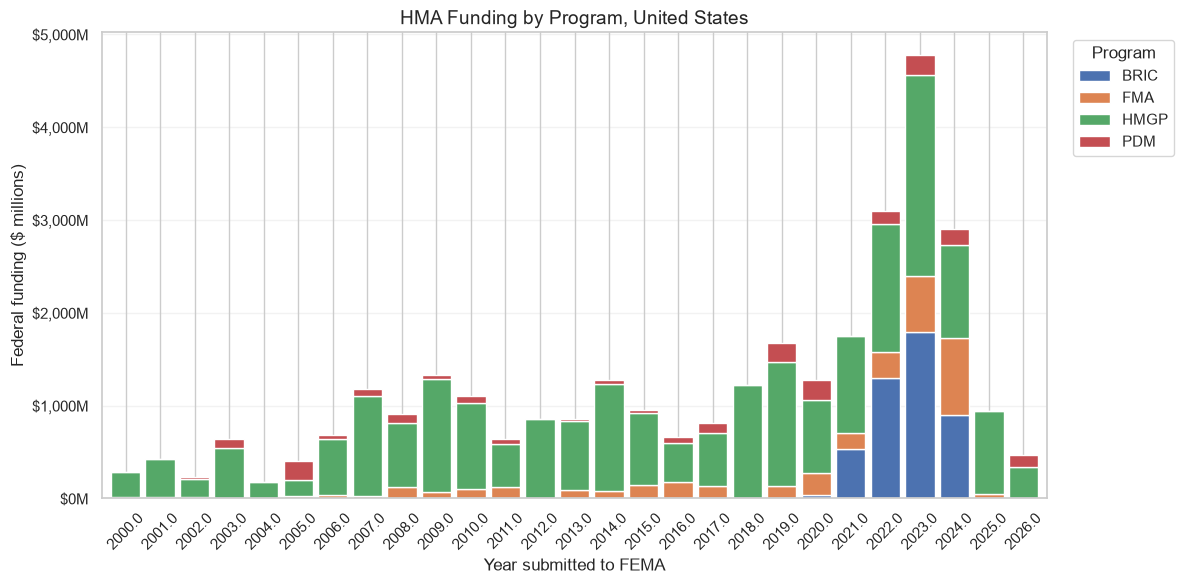

In [121]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Reshape data: years as rows, programs as columns
plot_data = (
    figure_7_data
    .pivot(
        index="year",
        columns="program",
        values="federal_share_amount"
    )
    .fillna(0)
    .sort_index()
)

# Create stacked bar chart
fig, ax = plt.subplots(figsize=(12, 6))

plot_data.div(1_000_000).plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.85
)

ax.set_title("HMA Funding by Program, United States", fontsize=14)
ax.set_xlabel("Year submitted to FEMA")
ax.set_ylabel("Federal funding ($ millions)")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}M")
)

ax.legend(
    title="Program",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


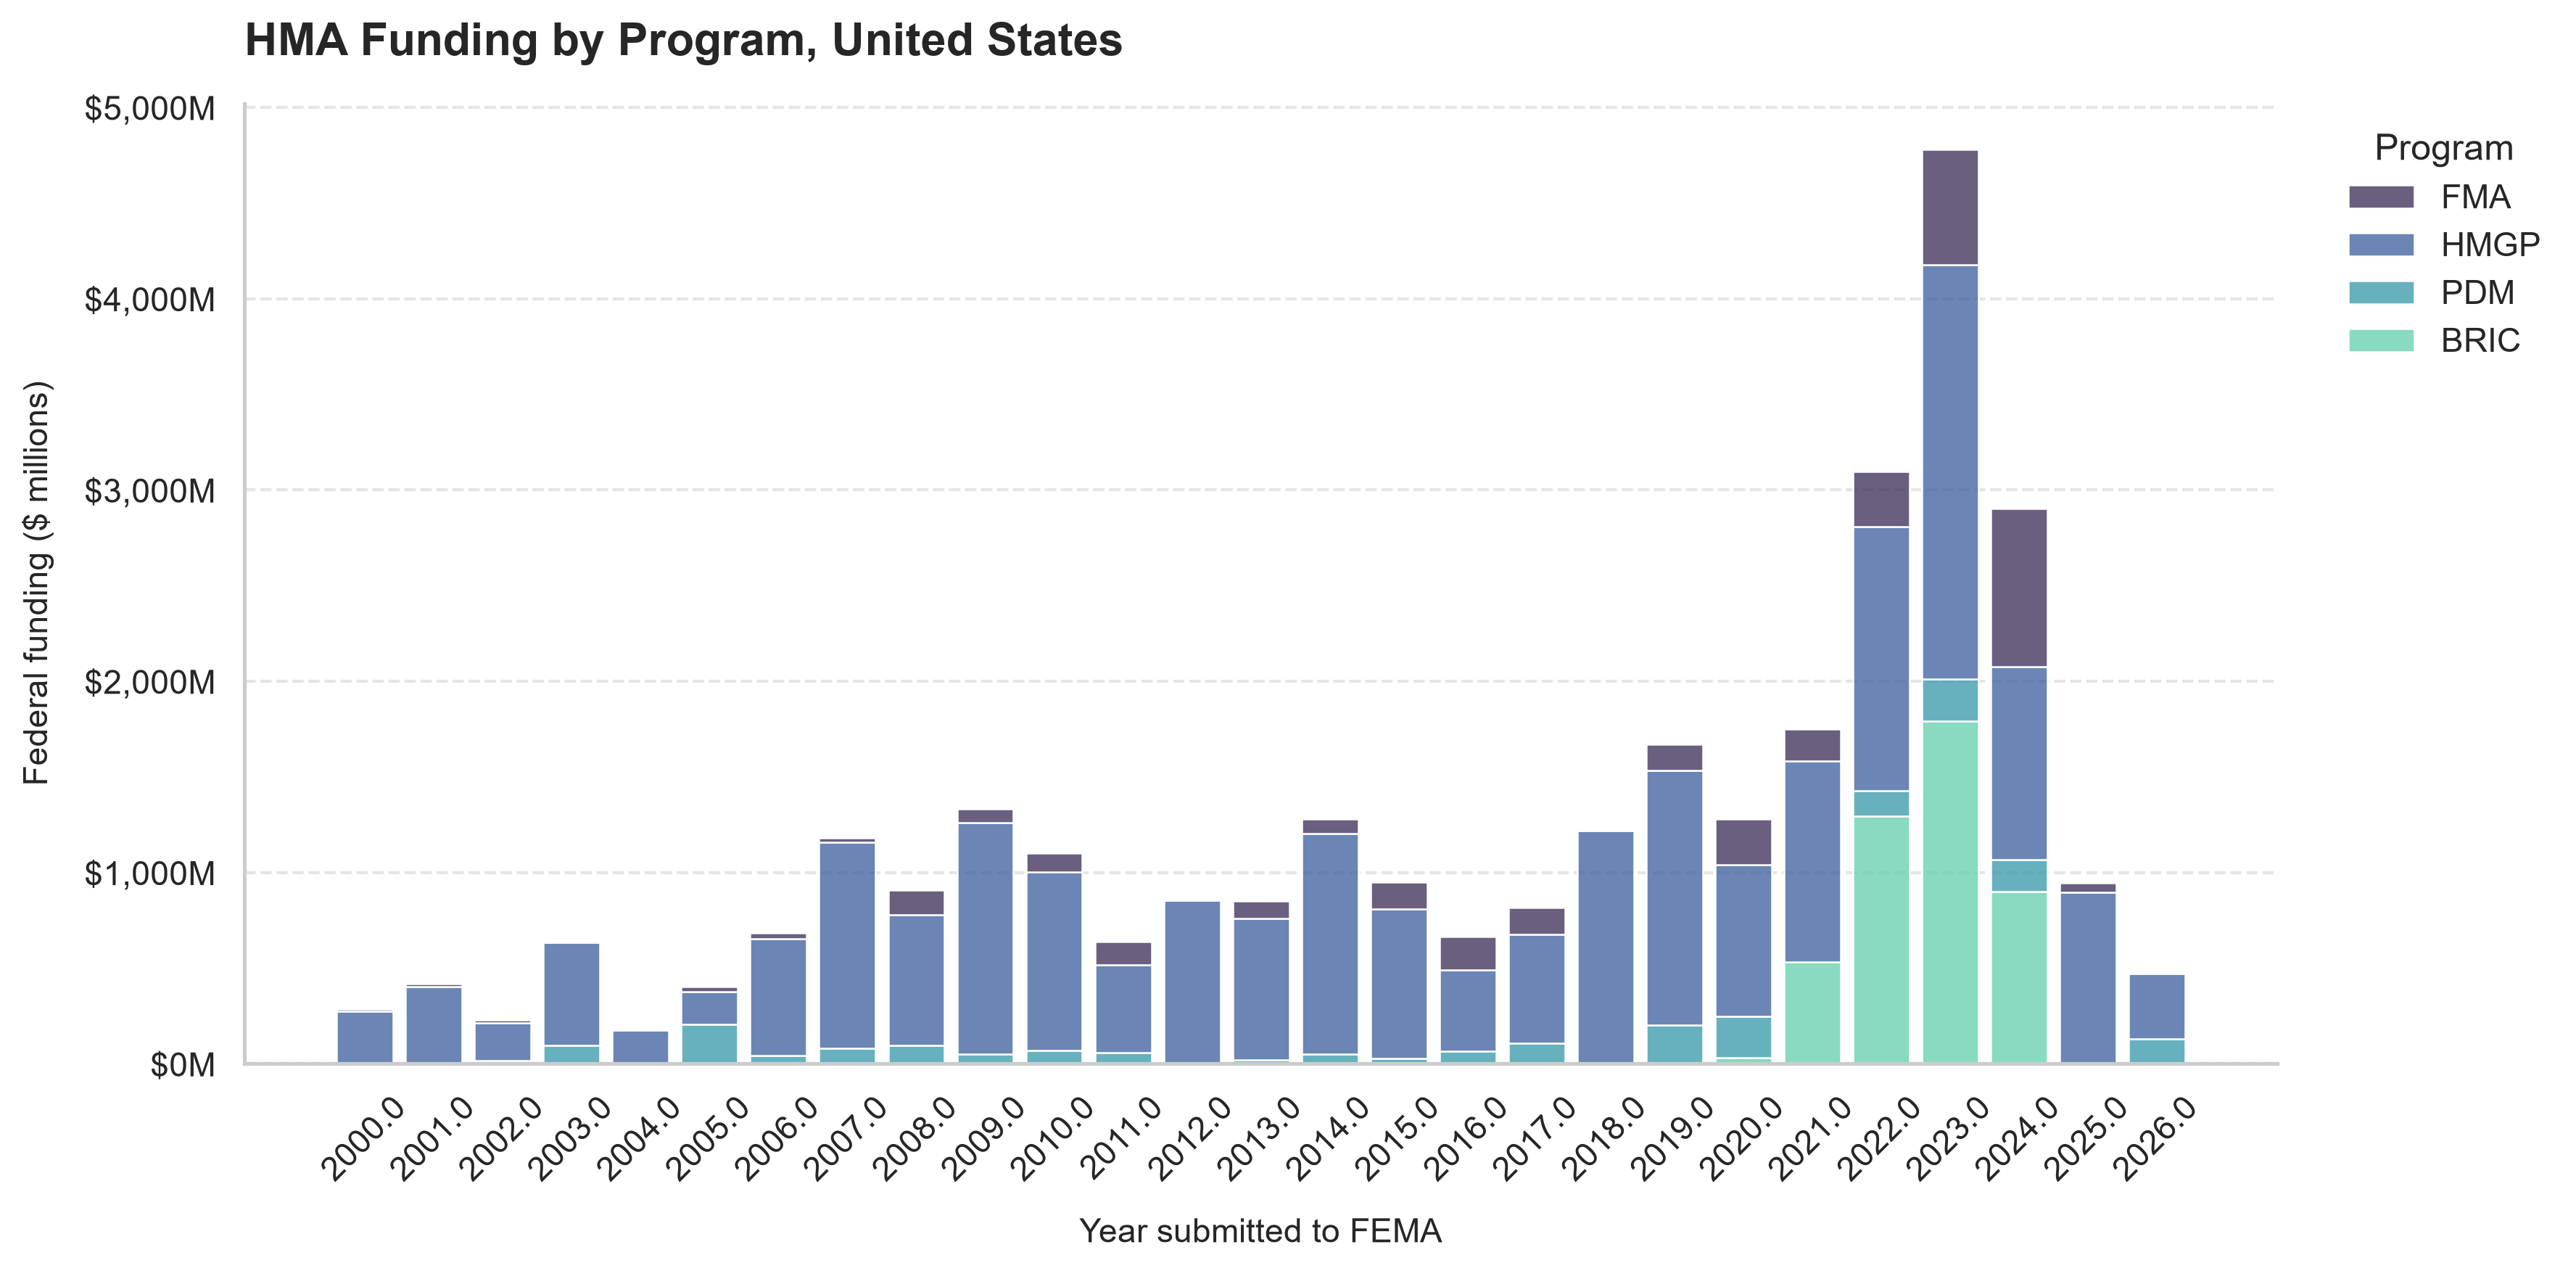

In [129]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

df_plot = figure_7_data.copy().sort_values("year")
df_plot["year_str"] = df_plot["year"].astype(str)
df_plot["funding_millions"] = df_plot["federal_share_amount"] / 1_000_000

fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

sns.histplot(
    data=df_plot,
    x="year_str",
    weights="funding_millions",
    hue="program",
    multiple="stack",
    palette="mako",      # Try "crest", "mako", or "Set2" as alternatives
    shrink=0.82,            
    edgecolor="white",      
    linewidth=0.6,
    ax=ax
)

ax.set_title("HMA Funding by Program, United States", fontsize=15, fontweight="bold", pad=16, loc="left")
ax.set_xlabel("Year submitted to FEMA", fontsize=11, labelpad=10)
ax.set_ylabel("Federal funding ($ millions)", fontsize=11, labelpad=10)

ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}M"))
ax.tick_params(axis="x", rotation=45)

sns.despine(top=True, right=True)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

sns.move_legend(
    ax,
    "upper left",
    bbox_to_anchor=(1.02, 1),
    title="Program",
    frameon=False
)

plt.tight_layout()
plt.show()


In [124]:
# Total funding by program
program_totals = (
    figure_7_data
    .groupby("program")["federal_share_amount"]
    .sum()
    .sort_values(ascending=False)
)

display(program_totals)

# Total funding by year
annual_totals = (
    figure_7_data
    .groupby("year")["federal_share_amount"]
    .sum()
)

display(annual_totals)

program
HMGP    2.143446e+10
BRIC    4.546410e+09
FMA     3.492262e+09
PDM     2.056763e+09
Name: federal_share_amount, dtype: float64

year
2000.0    2.865859e+08
2001.0    4.190213e+08
2002.0    2.293572e+08
2003.0    6.401821e+08
2004.0    1.790513e+08
2005.0    4.040708e+08
2006.0    6.827390e+08
2007.0    1.181355e+09
2008.0    9.063340e+08
2009.0    1.332932e+09
2010.0    1.101014e+09
2011.0    6.375729e+08
2012.0    8.599446e+08
2013.0    8.512661e+08
2014.0    1.279282e+09
2015.0    9.488102e+08
2016.0    6.658513e+08
2017.0    8.150071e+08
2018.0    1.217827e+09
2019.0    1.670024e+09
2020.0    1.277561e+09
2021.0    1.750927e+09
2022.0    3.095285e+09
2023.0    4.780836e+09
2024.0    2.901844e+09
2025.0    9.458842e+08
2026.0    4.693283e+08
Name: federal_share_amount, dtype: float64